In [1]:
import cPickle as pickle
import os

import numpy as np
import matplotlib
# matplotlib.use("Agg")
import matplotlib.pyplot as plt
from twpca import TWPCA
from twpca.regularizers import curvature

import soundsig
from soundsig.sound import spectrogram, plot_spectrogram
from soundsig.signal import lowpass_filter, highpass_filter

import config
from spikes.plotting import raster
from segment_analysis import MultiSegment
from segment_analysis.timewarp import WindowedTimeWarp

%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
BIRD_NAME = "LbY6074"
BIRD = "LbY6074__161215_145633"

In [3]:
DATADIR = config.DATADIR
data_path = os.path.join(DATADIR, "birds", BIRD_NAME, BIRD, "spikes", "{}-sorted.pkl".format(BIRD))

In [4]:
with open(data_path, "rb") as datafile:
    block = pickle.load(datafile)
block.create_relationship(recursive=True, force=True, append=True)

In [5]:
align4 = [0, 7, 16, 80]  # segments that play 4 motifs
align3 = [1, 9, 11, 19, 21, 68, 69, 71, 73, 74, 82, 95, 97, 98]  # segments that play 3 motifs
align2 = [2, 3, 4, 5, 8, 10, 12, 13, 17, 18, 20, 22, 67, 72, 85, 92, 93, 94, 99]  # segments that play 2 motifs
alignBOS = [14, 15, 23, 24, 26,28,29,30,32, 34, 35, 36, 37, 38, 39, 41, 42, 43, 44, 45, 47, 48, 49, 55]

In [6]:
print len(align4), len(align3)

4 14


In [7]:
iters = 100
window = 40000
overlap = 20000

## Response to tutor song

Example tutor song shown

* Spikes convolved with gaussian with width std=0.4ms

* N=18 songs


## Response to BOS

Onsets aligned, lots of variability in syllable timing though

* Spikes convolved with gaussian with width std=0.4ms

* N=24 songs

In [8]:
multiseg = MultiSegment(np.array(block.segments)[align2 + align3 + align4])
# multiseg = MultiSegment(np.array(block.segments)[alignBOS])
print multiseg

MultiSegment with 37 Segments, 13 Units, t_start=-0.0s, t_stop=4.9692s
{'vocalization_type': 'unknown', 'sound_type': 'live', 'vocalizer': 'unknown', 'playback_file': None}


# 1. Get analogsignals that will be aligned

Subtract mean right away

In [9]:
fs = np.round(multiseg.segments[0].analogsignals[0].sampling_rate.item())
times, analogsignals = zip(*[multiseg.get_analogsignal(s, 0, channel=0)[:2] for s in multiseg.segments])
for signal in analogsignals:
    signal -= np.mean(signal)

# 2. Pad with zeros or cut at min length or pad with NaNs

In [10]:
# Option 1: pad with zeros

maxlen = np.max([s.size for s in analogsignals])
analogsignals = np.array([np.pad(s,(0, maxlen-len(s)), 'constant') for s in analogsignals])
original_analogsignals = np.copy(analogsignals)

# Option 2: cut at min length
# minlen = np.min([s.size for s in analogsignals])
# analogsignals = np.array([s[:minlen] for s in analogsignals])

# Option 3: pad with NaNs
# maxlen = np.max([s.size for s in analogsignals])
# analogsignals = np.array([np.pad(s,(0, maxlen-len(s), np.nan), 'constant', constant_values=(0, np.nan)) for s in analogsignals])


# 3. Convert to amplitude envelope

In [11]:
for i, signal in enumerate(analogsignals):
    signal[:] = highpass_filter(signal, fs, 800)
    signal[:] = np.abs(lowpass_filter(signal, fs, 6000))
    signal[:] = lowpass_filter(signal, fs, 100)

In [12]:
# I'm just picking a silence threshold by histogramming amplitude values and picking a
# threshold a couple bins past the peak
amp_hist = np.histogram(analogsignals[0][np.where(analogsignals[0] > 0)], bins=200)
low_cut = amp_hist[1][np.argmax(amp_hist[0]) + 2]
print low_cut

0.00212664976716


# 4. Normalize amplitude envelope to mean

In [13]:
# low_cut = 0.003
for i, signal in enumerate(analogsignals):
    signal[np.where(signal < low_cut)] = 0
    signal[:] = signal / np.max(signal)

In [14]:
# for signal in original_analogsignals[:4]:
#     fig, ax = plt.subplots(figsize=(16, 1))
#     t, f, s, _ = spectrogram(signal, fs, 5000, 50.0, min_freq=0, max_freq=10000, nstd=6)
#     plot_spectrogram(t, f, s, colormap="gray_r", ax=ax, colorbar=False)
#     plt.ylabel("")
#     plt.xlabel("")
#     plt.yticks([])
#     plt.show()

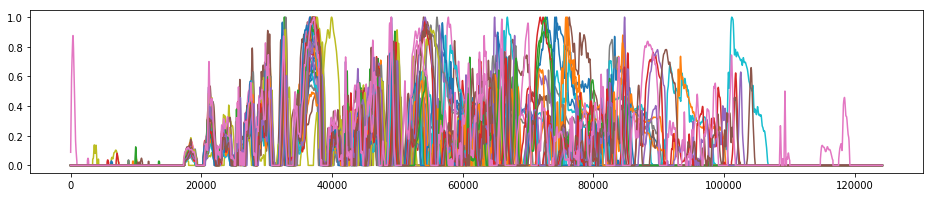

In [15]:
plt.figure(figsize=(16, 3))
for signal in analogsignals:
    plt.plot(signal)
plt.show()

## Warp data by amplitude envelope

In [16]:
model = WindowedTimeWarp(
    n_components=1,
    warptype="affine",
    warpinit="zero",
    warp_regularizer=curvature(scale=0.00001, power=1),
    time_regularizer=curvature(scale=0.00001, power=1, axis=0)
)

In [17]:
aligned_ampenv = model.fit_transform(analogsignals[:, :, None], 40000, 20000, lr=2e-2, niter=iters)

100%|██████████| 100/100 [00:04<00:00, 21.96it/s]


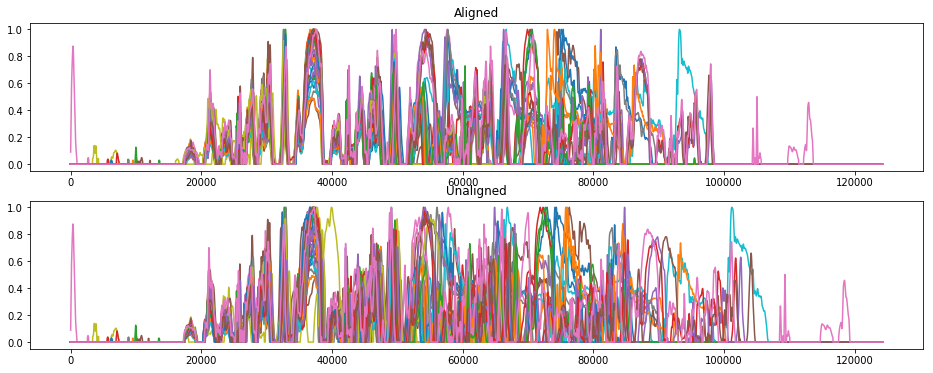

In [18]:
plt.figure(figsize=(16, 6))
plt.subplot(2, 1, 1)
for signal in aligned_ampenv:
    plt.plot(signal)
plt.title("Aligned")
plt.subplot(2, 1, 2)
for signal in analogsignals:
    plt.plot(signal)
plt.title("Unaligned")
plt.show()

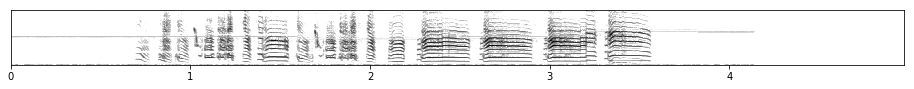

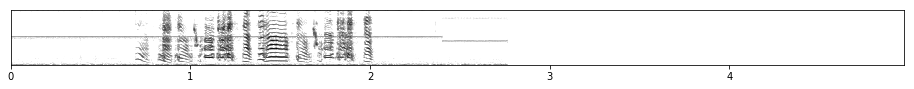

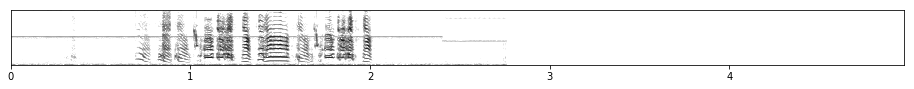

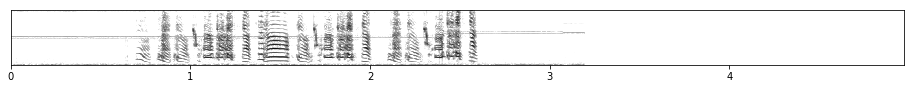

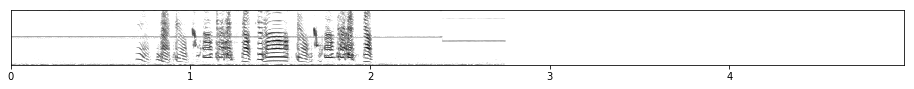

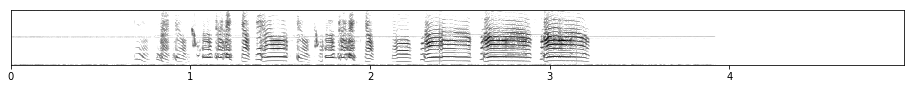

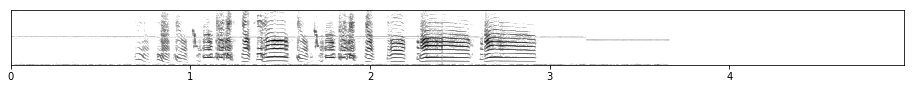

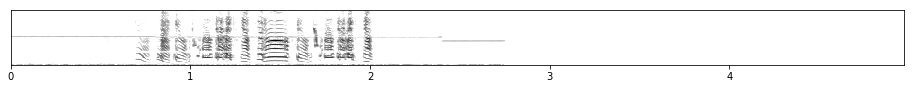

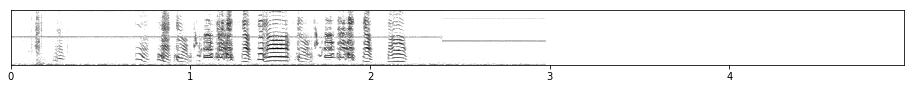

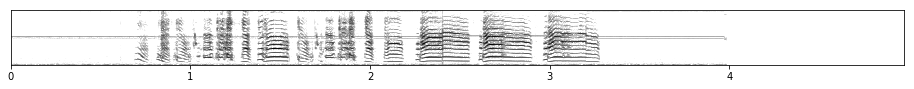

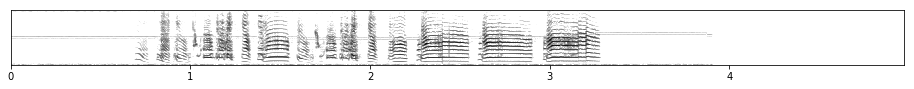

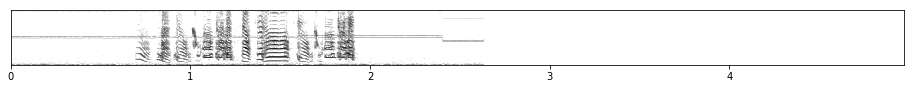

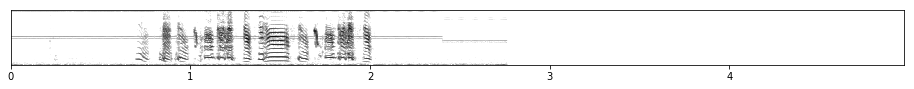

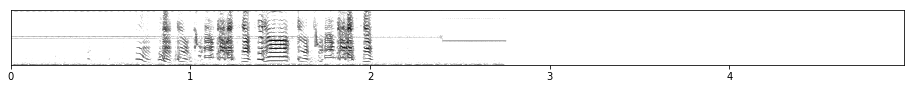

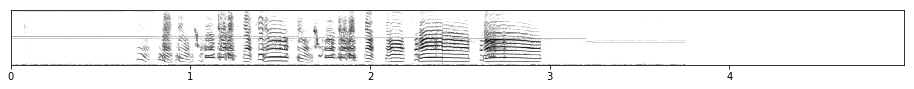

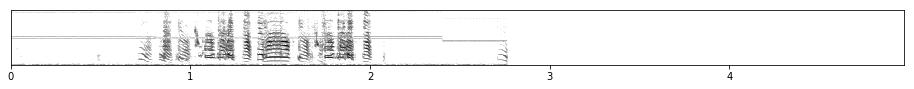

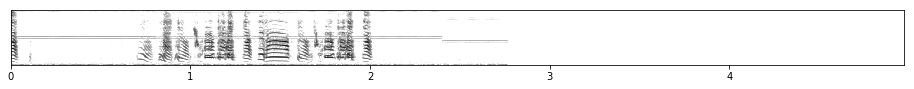

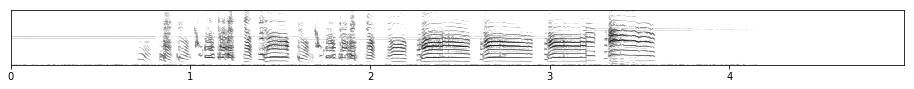

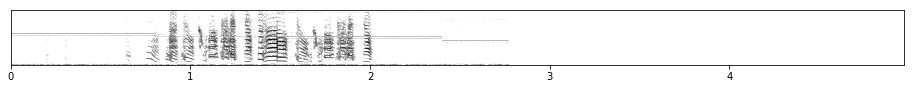

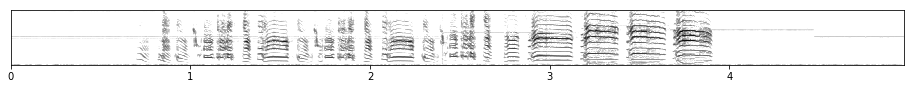

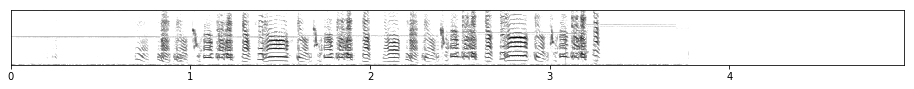

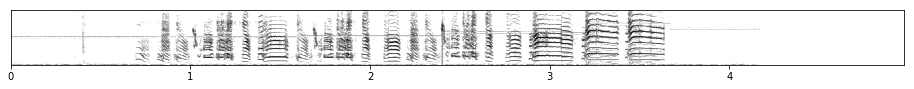

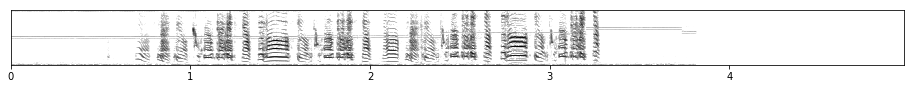

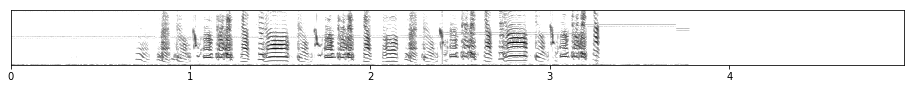

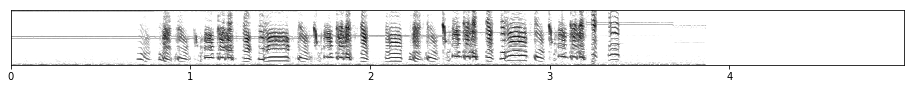

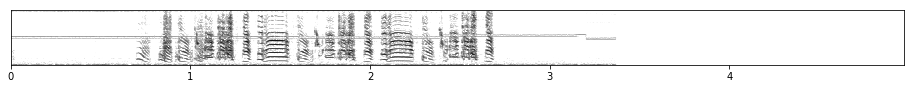

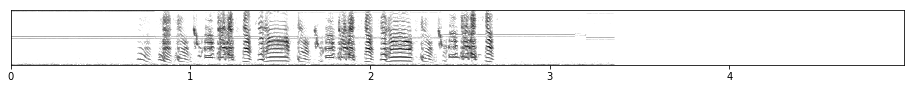

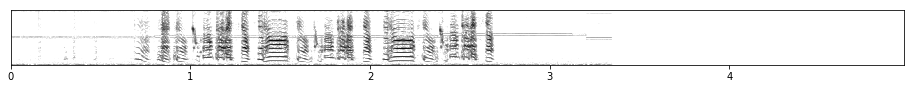

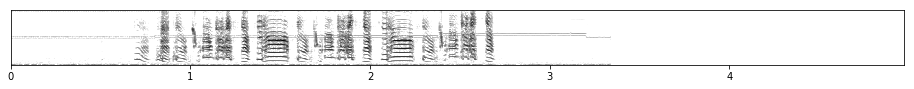

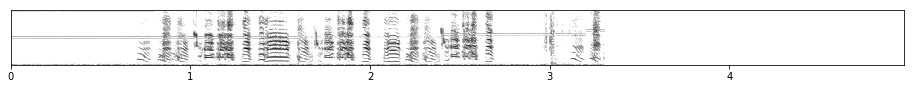

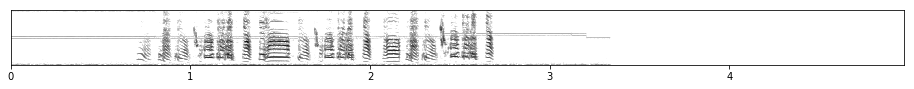

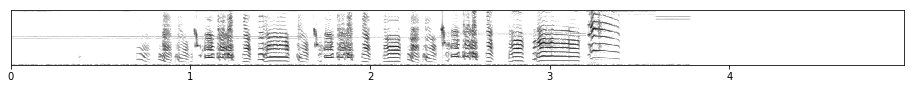

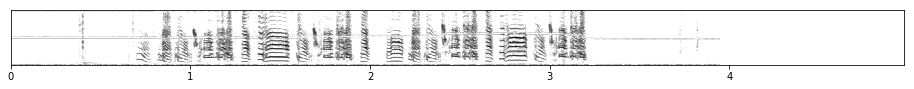

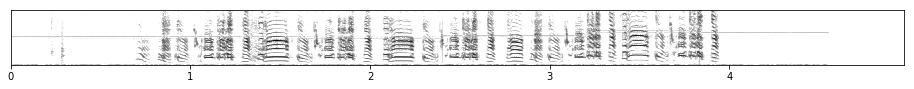

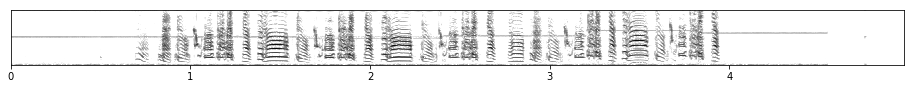

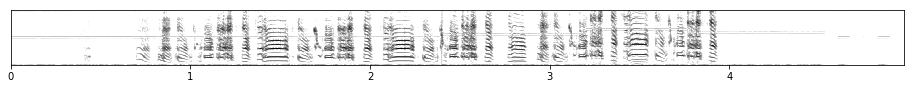

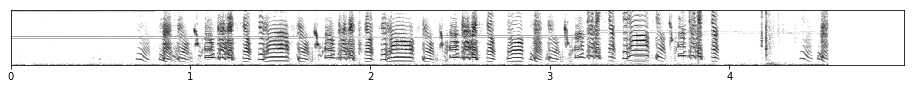

In [21]:
fitted_signals = model.transform(original_analogsignals[:, :, None])

for signal in fitted_signals[:, :, 0]:
    fig, ax = plt.subplots(figsize=(16, 1))
    t, f, s, _ = spectrogram(signal - np.mean(signal), fs, 5000, 50.0, min_freq=0, max_freq=10000, nstd=6)
    plot_spectrogram(t, f, s, colormap="gray_r", ax=ax, colorbar=False)
    plt.ylabel("")
    plt.xlabel("")
    plt.yticks([])
    plt.show()

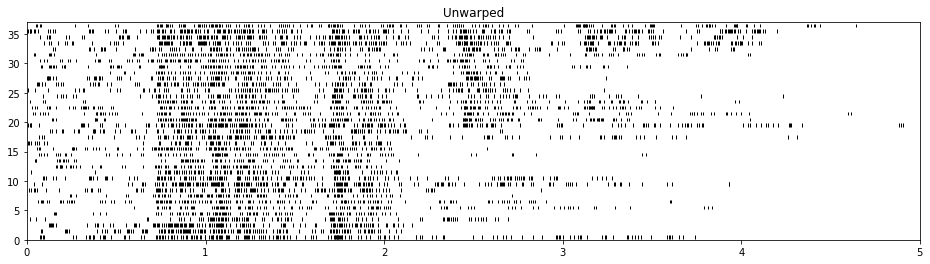

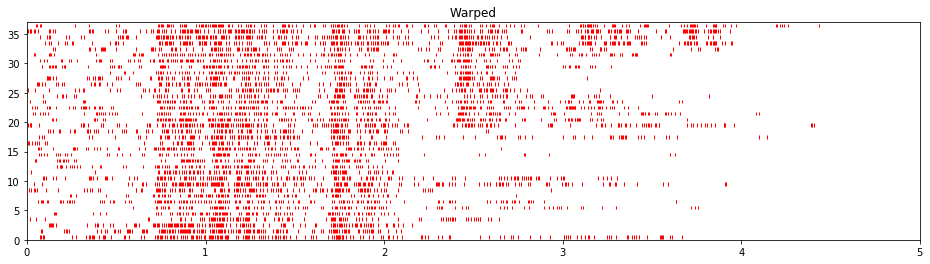

In [20]:
spike_times = multiseg.spike_times(unit=11)
warped_spike_times = model.convert_times(spike_times)

plt.figure(figsize=(16, 4))
multiseg.plotter.plot_raster(11)
plt.xlim(0, 5)
plt.title("Unwarped")
plt.show()

plt.figure(figsize=(16, 4))
raster.plot(warped_spike_times, color="Red")
plt.xlim(0, 5)
plt.title("Warped")
plt.show()